In [1]:
%matplotlib inline

In [2]:
import os
import io
import re
import itertools
import numpy as np
import pandas as pd
import json

In [3]:
data_sources = ['mnd_TSC']

distr_dims = ['-'.join(['Distancegroup', 'Legs', 'Timeperiodseq']),
              '-'.join(['Distancegroup', 'Legs'])]

aggr_levels = ['lsoa', 'msoa']
perc_sample_sizes = ['sample_perc_10']
export = False
out_folder = r'./outputs'
tolerance = 0.01

run_info = list(itertools.product(data_sources, distr_dims, aggr_levels, perc_sample_sizes))

In [4]:
def prepare_results_filepaths(run_results_fldr):
    flpaths = dict()
    flpaths['od'] = os.path.join(run_results_fldr, 'od_filtered.csv')
    flpaths['trs_obs_descr'] = os.path.join(run_results_fldr, 'trs_obs_descr.csv')
    flpaths['trs_obs_info'] = os.path.join(run_results_fldr, 'trs_obs_info.csv')
    flpaths['trs_mdl_descr'] = os.path.join(run_results_fldr, 'trs_mdl_descr.csv')
    flpaths['trs_mdl_info'] = os.path.join(run_results_fldr, 'trs_mdl_info.csv')
    flpaths['observed_distribution'] = os.path.join(run_results_fldr, 'target_distribution.csv')
    flpaths['optimisation_results'] = os.path.join(run_results_fldr, 'results.json')
    flpaths['trs_descr_comp'] = os.path.join(run_results_fldr, 'trs_descr_comp.csv')
    flpaths['metadata'] = os.path.join(run_results_fldr, 'metadata.json')
    return flpaths

In [5]:
def read_metadata(filepath):
    return pd.read_json(filepath, typ='series')

In [6]:
def read_zones_info(filepath, index_col='Zoneid'):
    return pd.read_csv(filepath, index_col=index_col)

In [7]:
def prepare_od_from_tours(trs_info, trs_descr, od_dims, name='Trips'):
    times_used = trs_info['Timesused']
    trs_descr = trs_descr.join(times_used)
    od = trs_descr.groupby(od_dims)['Timesused'].sum()
    od.name = name
    return od

In [8]:
def prepare_od_comparison(od_mdl, od_obs):
    od_obs.name = 'ObservedTrips'
    comp = od_obs.to_frame().join(od_mdl)
    comp.columns.name = 'TripsSource'
    comp = comp.stack()
    comp.name = 'Trips'
    return comp

In [9]:
def get_input_params_from_folder(infldr):
    fldrs = [name for name in os.listdir(infldr) if os.path.isdir(os.path.join(infldr, name))]
    inputs = []
    for fldr in fldrs:
        matches = re.findall('(\d+)legs-over(\d+)trips-distrConstr(\w+)', fldr)
        if matches:
            legs = int(matches[0][0])
            trips = int(matches[0][1])
            if matches[0][2] == 'True':
                distr_constr_enabled = True
            elif matches[0][2] == 'False':
                distr_constr_enabled = False
            else:
                raise ValueError('distrConstrEnabled must be either True or False')
                
            inputs.append([legs, trips, distr_constr_enabled])
        
    return inputs

In [10]:
def prepare_distribution_comparison(trs_mdl_info, obs_distr):
    
    obs_distr.drop(columns=['Size'], inplace=True)

    optim_distr = trs_mdl_info.groupby('Distrgroupid')['Timesused'].sum()
    optim_distr = optim_distr.div(optim_distr.sum())
    optim_distr.name = 'Percentage'
    
    # We need to identify the distribution dimensions cols (should be all apart form the Percentage)
    idx_cols = list()
    for c in obs_distr.columns:
        if c != 'Percentage':
            idx_cols.append(c)
    
    obs_distr.set_index(idx_cols, append=True).squeeze()
    
    distr_comp = obs_distr['Percentage'].to_frame().join(optim_distr, rsuffix='_')
    distr_comp.columns = ['obs', 'mdl']
    distr_comp.columns.name = 'Type'
    distr_comp = distr_comp.stack('Type')
    distr_comp.name = 'Percentage'

    return distr_comp

In [11]:
def collapse_tour_legs(trs, leg_descr_cols, idx_cols=['Tourid']):
    seqs = list()
    for c in leg_descr_cols:
        seq = trs.groupby(level=idx_cols)[c].apply(tuple)
        seqs.append(seq)
    
    trs_collapsed = pd.concat(seqs, axis=1)
    
    return trs_collapsed

In [12]:
def include_run_info(df, d_run_params):
    try:
        df = df.to_frame()
    except AttributeError:
        pass
    
    for k, v in d_run_params.items():
        df[k] = v
        
    df.set_index(list(d_run_params.keys()), append=True, inplace=True)
    df = df.squeeze()
    return df

In [13]:
def compare_times_used(comp_descr, trs_obs_info, trs_mdl_info,
                       leg_descr_cols, idx_cols):
    
    trs_obs_info['Type'] = 'obs'
    trs_mdl_info['Type'] = 'mdl'
    
    trs_obs_info.set_index('Type', append=True, inplace=True)
    trs_mdl_info.set_index('Type', append=True, inplace=True)
    trs_obs_info = trs_obs_info.swaplevel()
    trs_mdl_info = trs_mdl_info.swaplevel()
    
    times_used = pd.concat([trs_obs_info['Timesused'], 
                            trs_mdl_info['Timesused']])
    
    times_used = times_used[times_used!=0]
    
    # Keep only the used tours how='inner'
    df = comp_descrs.join(times_used, how='inner')
    df = collapse_tour_legs(df, leg_descr_cols, idx_cols)
    df = df.join(times_used)
    
    obs = df.xs('obs', level='Type', drop_level=False)
    mdl = df.xs('mdl', level='Type', drop_level=False)
    
    obs = obs.groupby(leg_descr_cols)['Timesused'].sum()
    mdl = mdl.groupby(leg_descr_cols)['Timesused'].sum()
    
    mrg = pd.merge(obs.to_frame(), mdl.to_frame(),
                   left_index=True, right_index=True,
                   how='outer',
                   suffixes=('_obs', '_mdl')).fillna(0)

    mrg.columns.name = 'Type'
    mrg.rename(columns=lambda x: x.replace('Timesused_', ''), inplace=True)
    mrg = mrg.stack()
    mrg.name = 'Timesused'

    df = mrg.unstack()
    df['Diff'] = df['obs'] - df['mdl']
    df['Diffabs'] = df['Diff'].abs()
    comp_times_used = df
    
    return comp_times_used

In [14]:
def prepare_run_info_dict(run_params):
    (data_source, distr_dims, aggr_level, sample_size,
     legs, trips_thresh, distr_constr_enabled) = run_params
    
    d_run_params = dict()
    d_run_params['DataSource'] = data_source
    d_run_params['AggrLevel'] = aggr_level
    d_run_params['SampleSize'] = sample_size
    d_run_params['DistrDims'] = distr_dims
    d_run_params['MaxLegs'] = int(legs)
    d_run_params['TripsThresh'] = int(trips_thresh)
    d_run_params['DistrConstr'] = distr_constr_enabled
    return d_run_params

In [15]:
def main(model_info):
    
    data_source, distr_dims, aggr_level, sample_size = model_info
    
    results_folder = r'../outputs/{}/{}/{}/{}'.format(data_source, distr_dims, aggr_level, sample_size)
    params = get_input_params_from_folder(results_folder)

    concat_od_mdl = list()
    concat_od_obs = list()

    concat_trs_mdl_used_descr = list()

    concat_comp_distrs = list()
    concat_comp_descrs = list()
    concat_comp_times_used = list()
    concat_metadata = list()
    
    for legs, trips_thresh, distr_constr_enabled in params:

        print(data_source, distr_dims, aggr_level, legs, trips_thresh, distr_constr_enabled)
        run_info = model_info.copy()
        
        run_tmplt = '{}legs-over{}trips-distrConstr{}'.format(legs, trips_thresh, distr_constr_enabled)
        run_results_fldr = os.path.join(results_folder, run_tmplt)

        flpaths = prepare_results_filepaths(run_results_fldr)
        metadata = read_metadata(flpaths['metadata'])
        
        obs_distr = pd.read_csv(flpaths['observed_distribution'], index_col='Distrgroupid')

        trs_obs_info = pd.read_csv(flpaths['trs_obs_info'], index_col=['Tourid'])
        trs_obs_descr = pd.read_csv(flpaths['trs_obs_descr'], index_col=['Tourid', 'Legidx'])
    
        trs_mdl_info = pd.read_csv(flpaths['trs_mdl_info'], index_col=['Tourid'])
        trs_mdl_descr = pd.read_csv(flpaths['trs_mdl_descr'], index_col=['Tourid', 'Legidx'])
    
        od_dims = ['Source', 'Target', 'Purpose', 'Direction', 'Timeperiod']
        
        # For the observed tours prepare the od only for the high frequency tours
        # trs_obs_info['Timesused'] = np.where(trs_obs_info['Inlowfreqgrp'], 0, 1)
        
        od_obs = prepare_od_from_tours(trs_obs_info, trs_obs_descr,
                                       od_dims=od_dims, name='ObservedTrips')
        
        od_mdl = prepare_od_from_tours(trs_mdl_info, trs_mdl_descr,
                                       od_dims=od_dims, name='ModelledTrips')
        
        if od_mdl is None:
            print('No results for legs:{}-trips:{}-distrConstr:{}'.format(legs, trips_thresh, distr_constr_enabled))
            continue

        comp_distr = prepare_distribution_comparison(trs_mdl_info, obs_distr)

        usecols = ['Tourid', 'Legidx',
                   'Source', 'Target', 'Purpose', 'Direction', 'Timeperiod',
                   'Timesused_mdl', 'Timesused_obs', 'Diff']
        
        comp_descr = pd.read_csv(flpaths['trs_descr_comp'],
                                 usecols=usecols,
                                 index_col=['Tourid', 'Legidx'])
        
        leg_descr_cols = ['Source', 'Timeperiod']
        idx_cols = ['Type', 'Tourid']
        #comp_times_used = compare_times_used(comp_descr,
        #                                     trs_obs_info, trs_mdl_info,
        #                                     leg_descr_cols, idx_cols)
        
        run_info.extend([legs, trips_thresh, distr_constr_enabled])
        d_run_info = prepare_run_info_dict(run_info)
        
        od_obs = include_run_info(od_obs, d_run_info)
        od_mdl = include_run_info(od_mdl, d_run_info)
        comp_distr = include_run_info(comp_distr, d_run_info)
        comp_descr = include_run_info(comp_descr, d_run_info)
        
        concat_metadata.append(metadata)
        concat_od_mdl.append(od_mdl)
        concat_od_obs.append(od_obs)
        concat_comp_descrs.append(comp_descr)
        concat_comp_distrs.append(comp_distr)
        
    metadata = pd.concat(concat_metadata, axis=1)
    od_mdl = pd.concat(concat_od_mdl)
    od_obs = pd.concat(concat_od_obs)

    comp_ods = prepare_od_comparison(od_mdl, od_obs)
    comp_distrs = pd.concat(concat_comp_distrs)
    comp_descrs = pd.concat(concat_comp_descrs)
    
    return metadata, comp_ods, comp_distrs, comp_descrs

In [16]:
comparisons = dict()

ods = list()
distrs = list()
descrs = list()
times_used = list()
metadata = list()

for ri in run_info:
    mdata, comp_ods, comp_distrs, comp_descrs = main(list(ri))    
    metadata.append(mdata)
    ods.append(comp_ods)
    distrs.append(comp_distrs)
    descrs.append(comp_descrs)
    #times_used.append(comp_times_used)

infolder = r'../inputs/mnd_TSC'
zones_info = read_zones_info(os.path.join(infolder, 'zones_info.csv'))
    
comparisons['metadata'] = pd.concat(metadata, axis=1)
comparisons['metadata'].columns = list(range(1, comparisons['metadata'].shape[1] + 1))
comparisons['metadata'].columns.name = 'RunId'
comparisons['ods'] = pd.concat(ods)
comparisons['distrs'] = pd.concat(distrs)
comparisons['descrs'] = pd.concat(descrs)
#comparisons['timesused'] = pd.concat(times_used)

if export:
    print('Exporting...')
    #mdl_nchains.to_csv(os.path.join(out_folder, 'optimisation_results.csv'), header=True, index=True)
    comparisons['metadata'].to_csv(os.path.join(out_folder, 'metadata.csv'), header=True)
    comparisons['ods'].to_csv(os.path.join(out_folder, 'comparison_od.csv'), header=True)
    comparisons['distrs'].to_csv(os.path.join(out_folder, 'comparison_distributions.csv'), header=True, index=True)
    comparisons['descrs'].to_csv(os.path.join(out_folder, 'comparison_descrs.csv'), header=True, index=True)
    #comparisons['timesused'].to_csv(os.path.join(out_folder, 'comparison_times_used.csv'), header=True, index=True)

mnd_TSC Distancegroup-Legs-Timeperiodseq lsoa 5 1 False
mnd_TSC Distancegroup-Legs-Timeperiodseq lsoa 5 1 True
mnd_TSC Distancegroup-Legs-Timeperiodseq msoa 5 1 False
mnd_TSC Distancegroup-Legs-Timeperiodseq msoa 5 1 True
mnd_TSC Distancegroup-Legs lsoa 5 1 False
mnd_TSC Distancegroup-Legs lsoa 5 1 True
mnd_TSC Distancegroup-Legs msoa 5 1 False
mnd_TSC Distancegroup-Legs msoa 5 1 True


In [17]:
df = comparisons['distrs'].copy()
df = df.xs(True, level='DistrConstr')
df = df.unstack('Type')
df['Diff_perc'] = df['obs'].sub(df['mdl'])

df['BelowTolerance'] = df.Diff_perc.abs() <= tolerance
df.dropna(inplace=True)
df['BelowTolerance'].all()

True

In [18]:
grpby_lvls = ['DataSource', 'DistrDims', 'AggrLevel', 'SampleSize',
              'MaxLegs', 'TripsThresh', 'DistrConstr',
              'TripsSource', 'Purpose']

df = comparisons['ods'].groupby(level=grpby_lvls).sum()

df = df.unstack('TripsSource')

df['Diff'] = df.ObservedTrips - df.ModelledTrips
df['Diff_perc'] = df.ModelledTrips/df.ObservedTrips - 1

df.style.format({
    'ModelledTrips': '{:,.0f}'.format,
    'ObservedTrips': '{:,.0f}'.format,
    'Diff': '{:,.0f}'.format,
    'Diff_perc': '{:.0%}'.format
})

In [19]:
filters = dict()
filters['DataSource'] = 'mnd_TSC'
filters['DistrDims'] = 'Distancegroup-Legs-Timeperiodseq'
filters['AggrLevel'] = 'lsoa'
filters['SampleSize'] = 'sample_perc_10'
filters['MaxLegs'] = 5
filters['TripsThresh'] = 1
filters['DistrConstr'] = True

In [20]:
if filters:
    comparisons_filt = dict()
    for k, f in comparisons.items():
        if k!='metadata':
            comparisons_filt[k] = comparisons[k].xs(list(filters.values()),
                                                level=list(filters.keys()))
    analysis_comp = comparisons_filt.copy()
else:
    analysis_comp = comparisons.copy()

In [21]:
grpby_lvls = ['DataSource', 'AggrLevel', 'SampleSize',
              'MaxLegs', 'TripsThresh', 'DistrConstr']

grpby_lvls = [gl for gl in grpby_lvls if gl not in list(filters.keys())]

# can just unstack and plot(subplots=True)
if grpby_lvls:
    dfg = analysis_comp['distrs'].groupby(level=grpby_lvls)
    for k, g in dfg:
        print(k)
        plt = g.unstack('Type')
        plt.plot(kind='bar')

In [22]:
#grpby_lvls = ['MaxLegs', 'TripsThresh', 'DistrConstr', 'Inboth']
#grpby_lvls = [gl for gl in grpby_lvls if gl not in list(filters.keys())]
#analysis_comp['descrs'].groupby(grpby_lvls).size().unstack('DistrConstr')

In [23]:
def zone_in_tour(tr, zone):
    return zone in tr.Source.values

In [25]:
df = analysis_comp['descrs'].copy()
df = df[df.Diff!=0]

#slc = pd.IndexSlice
#start_zones = df.loc(axis=0)[]

#filetr_zone = 'E01014405'
filter_zone = None
if filter_zone:
    in_tr = df.groupby(level=0).apply(zone_in_tour, zone=filter_zone)
    in_tr.name = 'Intour'
    df = df.join(in_tr)
    df = df[df['Intour']]



In [26]:
mdl = df[df.Timesused_mdl!=0]
obs = df[df.Timesused_obs!=0]

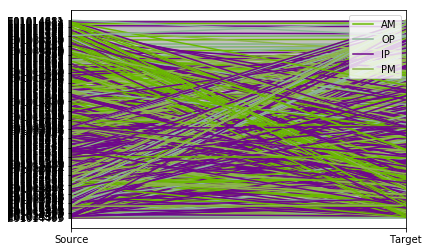

In [27]:
pd.plotting.parallel_coordinates(mdl, 'Timeperiod', cols=['Source', 'Target'], sort_labels=True)

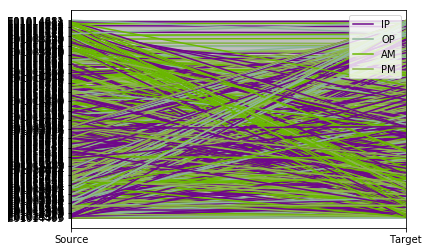

In [28]:
pd.plotting.parallel_coordinates(obs, 'Timeperiod', cols=['Source', 'Target'], sort_labels=True)

C:\ProgramData\Miniconda3\envs\phd\lib\site-packages\matplotlib\axes\_base.py:3152: UserWarning: Attempting to set identical left==right results
in singular transformations; automatically expanding.
left=0, right=0
  'left=%s, right=%s') % (left, right))


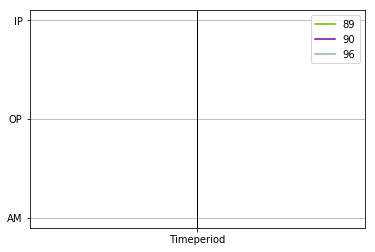

In [36]:
df = analysis_comp['descrs'].copy()
df = df[df.Diff!=0]
df = df.reset_index().head()
pd.plotting.parallel_coordinates(df, 'Tourid', cols=['Timeperiod'], sort_labels=True)

In [93]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

C:\ProgramData\Miniconda3\envs\phd\lib\site-packages\ipykernel_launcher.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy


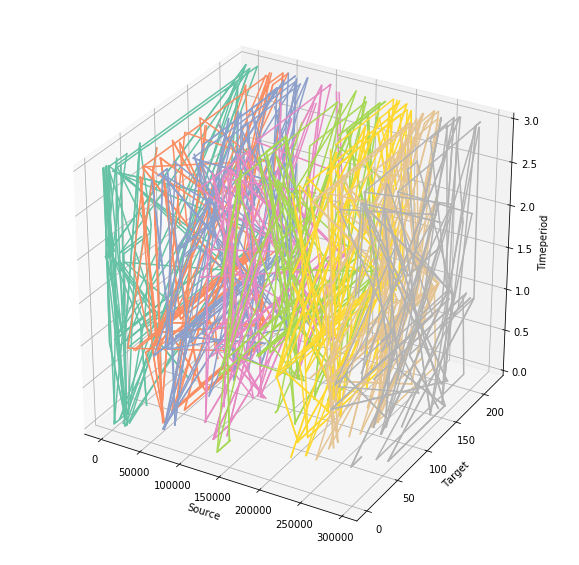

In [192]:
cat_cols = ['Source', 'Target', 'Timeperiod']
df = analysis_comp['descrs'].copy()
df = df[df.Diff!=0]

filter_zone = 'E01014405'
filter_zone = None
if filter_zone:
    in_tr = df.groupby(level=0).apply(zone_in_tour, zone=filter_zone)
    in_tr.name = 'Intour'
    df = df.join(in_tr)
    df = df[df['Intour']]

for c in cat_cols:
    df[c] = df[c].astype('category').cat.codes

#df = df.head()
#df = df.head(50)
df.index = df.index.remove_unused_levels()

# Unique category labels: 'D', 'F', 'G', ...
colour_labels = df.index.levels[0].unique()

# List of RGB triplets
colours = plt.cm.get_cmap('Set2', len(colour_labels))

# Map label to RGB
#colour_map = dict(zip(colour_labels, colours))

# Finally use the mapped values
#plt.scatter(df['carat'], df['price'], c=df['color'].map(colour_map))

fig = plt.figure(figsize=(10,10))
threedee = fig.add_subplot(111, projection='3d')

#threedee = plt.figure().gca(projection='3d')
i = 0
for k, g in df.groupby(level='Tourid'):
    g['id'] = k
    threedee.plot(g['id'], g['Source'], g['Timeperiod'], c=colours(i))
    i+=1

#threedee.scatter(df['Source'], df['Target'], df['Timeperiod'])
threedee.set_xlabel('Source')
threedee.set_ylabel('Target')
threedee.set_zlabel('Timeperiod')
plt.show()

In [184]:
df

Source  Target Purpose     Direction  Timeperiod  \
Tourid Legidx                                                     
89     0            1       2      HB      FromHome           0   
       1            2       1      HB        ToHome           2   
90     0            1       2      HB      FromHome           1   
       1            2       1      HB        ToHome           2   
96     0            1       2      HB      FromHome           0   
       1            2       0     NHB  NonHomeBased           3   
       2            0       1      HB        ToHome           2   
98     0            1       2      HB      FromHome           1   
       1            2       0     NHB  NonHomeBased           3   
       2            0       1      HB        ToHome           2   

               Timesused_mdl  Timesused_obs  Diff  Intour  
Tourid Legidx                                              
89     0                 1.0            0.0   1.0    True  
       1                 1.0            0.0   1.0    True  
90     0                 0.0            1.0  -1.0    True  
       1                 0.0            1.0  -1.0    True  
96     0                 0.0            1.0  -1.0    True  
       1                 0.0            1.0  -1.0    True  
       2                 0.0            1.0  -1.0    True  
98     0                 1.0            0.0   1.0    True  
       1                 1.0            0.0   1.0    True  
       2                 1.0            0.0   1.0    True

In [95]:
grpby_cols = ['DataSource', 'AggrLevel', 'SampleSize',
              'DistrDims', 'MaxLegs', 'TripsThresh']#, 'DistrConstr']

comparisons['timesused'].xs(True, level='DistrConstr').groupby(level=grpby_cols).sum()

KeyError: 'timesused'

In [97]:
# Calculate number of missing tours 
grpby_lvls = ['DataSource', 'AggrLevel', 'SampleSize',
              'DistrDims', 'MaxLegs', 'TripsThresh', 'DistrConstr']

df = comparisons['timesused'].copy()
df = df.Diff.groupby(level=grpby_lvls).value_counts()
df.name = 'Count'
df = df.reset_index(level='Diff')
df = df.product(axis=1)
df.name = 'MissingTours'
df.groupby(level=grpby_lvls).sum()

DataSource  AggrLevel  SampleSize      DistrDims                         MaxLegs  TripsThresh  DistrConstr
mnd_TSC     lsoa       sample_perc_10  Distancegroup-Legs                5        1            False           83.0
                                                                                               True            86.0
                                       Distancegroup-Legs-Timeperiodseq  5        1            False            0.0
                                                                                               True             0.0
            msoa       sample_perc_10  Distancegroup-Legs                5        1            False           79.0
                                                                                               True            82.0
                                       Distancegroup-Legs-Timeperiodseq  5        1            False          118.0
                                                                                 

In [135]:
df = comparisons['timesused'].copy()
grpby_lvls = list(df.index.names)
grpby_lvls.remove('Timeperiod')

df = df.groupby(level=grpby_lvls).sum()
df.Diff = df.obs - df.mdl
df.Diffabs = abs(df.Diff)
df = df[df.Diff!=0]

KeyError: 'timesused'

In [113]:
df2 = df.copy()
idx_lvls = ['AggrLevel', 'SampleSize', 'DistrDims', 'MaxLegs', 'TripsThresh', 'DistrConstr']
df2['Tourid'] = df2.groupby(level=idx_lvls).cumcount()
df2.set_index('Tourid', append=True, inplace=True)
#df2 = df2.reset_index()
#s = df2.Source.apply(pd.Series)
#s.name = 'Legidx'
df2

Type                                                                                                                                                            obs  \
Source                                             DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh DistrConstr Tourid        
(E01014396, E01014370, E01014396, E01014370)       mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           True        0       0.0   
(E01014396, E01014370, E01014542, E01014396, E0... mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False       0       0.0   
(E01014396, E01014370, E01014542, E01014531, E0... mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False       1       1.0   
                                                                                                                                            True        1       1.0   
(E01014396, E01014392, E01014370, E01014403, E0... mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False       0       0.0   
                                                                                                                                            True        0       0.0   
(E01014396, E01014392, E01033358, E01014370, E0... mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           True        2       1.0   
(E01014396, E01014392, E01033358, E01014542, E0... mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           True        3       0.0   
(E01014396, E01014403, E01014396, E01014403)       mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False       2       1.0   
                                                                                                                                            True        4       1.0   
(E01014396, E01014403, E01014526, E01014396, E0... mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False       3       0.0   
                                                                                                                                            True        5       0.0   
(E01014396, E01014542, E01014396, E01014542)       mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False       4       1.0   
                                                                                                                                            True        6       1.0   
(E01014396, E01014542, E01014531, E01014396, E0... mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False       5       0.0   
                                                                                                                                            True        7       0.0   
(E01014396, E01014727, E01014558, E01014498, E0... mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs               5       1           False       0       0.0   
                                                                                                                                            True        0       0.0   
(E01014396, E01014885, E01033347, E01014540, E0... mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs               5       1           False       1       0.0   
                                                                                                                                            True        1       0.0   
(E01014396, E01014994, E01033331, E01014542, E0... mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs               5       1           False       2       0.0   
                                                                                                                                            True        2      

In [ ]:
df = comparisons['descrs'].copy()
df.head()

In [ ]:
df = comparisons['timesused'].copy()
df.head()

In [ ]:
df = comparisons['descrs'].copy()
cat_cols = ['Source', 'Target', 'Purpose', 'Direction', 'Timeperiod']
tup_cols = ['Source', 'Timeperiod'] 
df = df[tup_cols].groupby(level=list(set(df.index.names)^set(['Legidx']))).agg(tuple)
df.head()

In [ ]:
df = comparisons['ods'].copy()
df = df.xs(['ObservedTrips', True, 'Distancegroup-Legs-Timeperiodseq'],
           level=['TripsSource', 'DistrConstr', 'DistrDims'])

grpby_lvls = ['DataSource', 'AggrLevel', 'SampleSize', 'MaxLegs', 'TripsThresh']

vcnts = df.groupby(level=grpby_lvls).value_counts()
tots_gs = vcnts.groupby(level=grpby_lvls).apply(lambda x: x.div(x.sum()))


In [ ]:
tots_gs.unstack('AggrLevel').plot(kind='bar', subplots=True)